 Config MLflow

In [2]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("Sentiment_Classical_ML_Darija")

print("✅ MLflow configuré")

c:\Users\elham\Desktop\youtube-sentiment-analysis\.venv\Lib\site-packages\mlflow\tracking\_tracking_service\utils.py:184: FutureWarning: The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri, store_uri)
2026/05/01 12:28:09 INFO mlflow.tracking.fluent: Experiment with name 'Sentiment_Classical_ML_Darija' does not exist. Creating a new experiment.


✅ MLflow configuré


Chargement des CSV

In [13]:
import pandas as pd

train_path = r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv"
val_path   = r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv"
test_path  = r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv"

train_df = pd.read_csv(train_path)
val_df   = pd.read_csv(val_path)
test_df  = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Val shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nColonnes:", train_df.columns.tolist())

Train shape: (58387, 3)
Val shape: (12512, 3)
Test shape: (12512, 3)

Colonnes: ['comment_id', 'text', 'label']


Première expérience avec GridSearchCV + MLflow

In [6]:
# ==============================
# 1 Imports
# ==============================
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

import mlflow
import mlflow.sklearn


# ==============================
# 2 Load Data
# ==============================
train_df = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv")
val_df   = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv")
test_df  = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val     = val_df["text"], val_df["label"]
X_test, y_test   = test_df["text"], test_df["label"]


# ==============================
# 3 MLflow
# ==============================
mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("sentiment-analysis-optimized")


with mlflow.start_run(run_name="LogReg_TFIDF_RandomSearch"):

    # ==============================
    # 4 Pipeline
    # ==============================
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_df=0.9,
            min_df=5
        )),
        ("clf", LogisticRegression(max_iter=1000))
    ])

    # ==============================
    # 5 Hyperparameter space (réduit)
    # ==============================
    param_dist = {
        "tfidf__ngram_range": [(1,1), (1,2)],
        "tfidf__max_features": [3000, 5000],
        "clf__C": [0.1, 1, 10]
    }

    # ==============================
    # 6 RandomizedSearch (PLUS RAPIDE)
    # ==============================
    search = RandomizedSearchCV(
        pipeline,
        param_distributions=param_dist,
        n_iter=5,          # seulement 5 essais
        cv=2,              # réduit pour vitesse
        scoring="f1_weighted",
        n_jobs=2,          # évite freeze CPU
        verbose=1,
        random_state=42
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_

    # ==============================
    # 7 Validation
    # ==============================
    y_val_pred = best_model.predict(X_val)

    accuracy = accuracy_score(y_val, y_val_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, y_val_pred, average="weighted"
    )

    print("\n===== VALIDATION =====")
    print("Accuracy:", accuracy)
    print("F1:", f1)

    print("\nClassification report:\n", classification_report(y_val, y_val_pred))

    # ==============================
    # 8 Test final
    # ==============================
    y_test_pred = best_model.predict(X_test)

    test_acc = accuracy_score(y_test, y_test_pred)
    test_f1 = precision_recall_fscore_support(
        y_test, y_test_pred, average="weighted"
    )[2]

    print("\n===== TEST =====")
    print("Test Accuracy:", test_acc)
    print("Test F1:", test_f1)

    # ==============================
    # 9 MLflow logs
    # ==============================
    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("vectorizer", "TFIDF")

    mlflow.log_metric("val_accuracy", accuracy)
    mlflow.log_metric("val_f1", f1)

    mlflow.log_metric("test_accuracy", test_acc)
    mlflow.log_metric("test_f1", test_f1)

    mlflow.sklearn.log_model(best_model, "model")

    print("\nRun terminé ")

2026/05/01 19:46:33 INFO mlflow.tracking.fluent: Experiment with name 'sentiment-analysis-optimized' does not exist. Creating a new experiment.


Fitting 2 folds for each of 5 candidates, totalling 10 fits

===== VALIDATION =====
Accuracy: 0.6572890025575447
F1: 0.658433456573247

Classification report:
               precision    recall  f1-score   support

     negatif       0.64      0.63      0.64      4174
      neutre       0.59      0.63      0.61      4044
     positif       0.75      0.71      0.73      4294

    accuracy                           0.66     12512
   macro avg       0.66      0.66      0.66     12512
weighted avg       0.66      0.66      0.66     12512



2026/05/01 19:47:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



===== TEST =====
Test Accuracy: 0.6538523017902813
Test F1: 0.6549248715882935


2026/05/01 19:47:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Run terminé 


 Expérience 2 : Embeddings + Logistic Regression

In [7]:
# ==============================
# 1 Imports
# ==============================
import pandas as pd
import numpy as np
import mlflow
import mlflow.sklearn

from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
)
from sklearn.model_selection import RandomizedSearchCV


# ==============================
# 2 Load Data
# ==============================
train_df = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv")
val_df   = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv")
test_df  = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv")

X_train_text, y_train = train_df["text"], train_df["label"]
X_val_text, y_val     = val_df["text"], val_df["label"]
X_test_text, y_test   = test_df["text"], test_df["label"]


# ==============================
# 3 Generate Embeddings
# ==============================
print("Loading embedding model...")
model_emb = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

print("Encoding train...")
X_train = model_emb.encode(X_train_text.tolist(), show_progress_bar=True)

print("Encoding val...")
X_val = model_emb.encode(X_val_text.tolist(), show_progress_bar=True)

print("Encoding test...")
X_test = model_emb.encode(X_test_text.tolist(), show_progress_bar=True)


# ==============================
# 4 MLflow
# ==============================
mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("sentiment-analysis-embeddings")


with mlflow.start_run(run_name="LogReg_Embeddings"):

    # ==============================
    # 5 Logistic Regression
    # ==============================
    param_dist = {
        "C": [0.1, 1, 10]
    }

    clf = RandomizedSearchCV(
        LogisticRegression(max_iter=1000),
        param_distributions=param_dist,
        n_iter=3,
        cv=2,
        scoring="f1_weighted",
        random_state=42
    )

    clf.fit(X_train, y_train)

    best_model = clf.best_estimator_

    # ==============================
    # 6 Validation
    # ==============================
    y_val_pred = best_model.predict(X_val)

    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = precision_recall_fscore_support(
        y_val, y_val_pred, average="weighted"
    )[2]

    print("\n===== VALIDATION =====")
    print("Accuracy:", val_acc)
    print("F1:", val_f1)

    # ==============================
    # 7 Test
    # ==============================
    y_test_pred = best_model.predict(X_test)

    test_acc = accuracy_score(y_test, y_test_pred)
    test_f1 = precision_recall_fscore_support(
        y_test, y_test_pred, average="weighted"
    )[2]

    print("\n===== TEST =====")
    print("Test Accuracy:", test_acc)
    print("Test F1:", test_f1)

    # ==============================
    # 8 MLflow Logs
    # ==============================
    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("vectorizer", "Embeddings")
    mlflow.log_param("embedding_model", "paraphrase-multilingual-MiniLM-L12-v2")

    mlflow.log_metric("val_accuracy", val_acc)
    mlflow.log_metric("val_f1", val_f1)

    mlflow.log_metric("test_accuracy", test_acc)
    mlflow.log_metric("test_f1", test_f1)

    mlflow.sklearn.log_model(best_model, "model")

    print("\nRun terminé")

c:\Users\elham\Desktop\youtube-sentiment-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading embedding model...


c:\Users\elham\Desktop\youtube-sentiment-analysis\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\elham\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:0

Encoding train...


Batches: 100%|██████████| 1825/1825 [16:11<00:00,  1.88it/s]


...

Encoding test...


Batches: 100%|██████████| 391/391 [04:50<00:00,  1.34it/s]
2026/05/01 20:34:05 INFO mlflow.tracking.fluent: Experiment with name 'sentiment-analysis-embeddings' does not exist. Creating a new experiment.
2026/05/01 20:35:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



===== VALIDATION =====
Accuracy: 0.5847186700767263
F1: 0.5848696647448722

===== TEST =====
Test Accuracy: 0.5852781329923273
Test F1: 0.5851218907956621


2026/05/01 20:35:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Run terminé


SVM (LinearSVC) + TF‑IDF

In [8]:
# ==============================
# SVM + TF-IDF
# ==============================

import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import precision_recall_fscore_support

train_df = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv")
val_df   = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv")
test_df  = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val     = val_df["text"], val_df["label"]
X_test, y_test   = test_df["text"], test_df["label"]

mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("sentiment-analysis-tfidf-models")

with mlflow.start_run(run_name="SVM_TFIDF"):

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_df=0.9, min_df=5)),
        ("clf", LinearSVC())
    ])

    param_dist = {
        "tfidf__ngram_range": [(1,1), (1,2)],
        "clf__C": [0.1, 1, 10]
    }

    search = RandomizedSearchCV(
        pipeline, param_distributions=param_dist,
        n_iter=5, cv=2, scoring="f1_weighted", random_state=42
    )

    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    val_f1 = precision_recall_fscore_support(y_val, best_model.predict(X_val), average="weighted")[2]
    test_f1 = precision_recall_fscore_support(y_test, best_model.predict(X_test), average="weighted")[2]

    mlflow.log_metric("val_f1", val_f1)
    mlflow.log_metric("test_f1", test_f1)
    mlflow.sklearn.log_model(best_model, "model")

    print("SVM Test F1:", test_f1)

2026/05/01 20:37:11 INFO mlflow.tracking.fluent: Experiment with name 'sentiment-analysis-tfidf-models' does not exist. Creating a new experiment.
2026/05/01 20:37:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/01 20:37:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


SVM Test F1: 0.6914439853424869


Naive Bayes + TF‑IDF

In [9]:
# ==============================
# Naive Bayes + TF-IDF
# ==============================

import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import precision_recall_fscore_support

train_df = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv")
val_df   = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv")
test_df  = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val     = val_df["text"], val_df["label"]
X_test, y_test   = test_df["text"], test_df["label"]

mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("sentiment-analysis-tfidf-models")

with mlflow.start_run(run_name="NaiveBayes_TFIDF"):

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_df=0.9, min_df=5)),
        ("clf", MultinomialNB())
    ])

    param_dist = {
        "clf__alpha": [0.5, 1.0]
    }

    search = RandomizedSearchCV(
        pipeline, param_distributions=param_dist,
        n_iter=2, cv=2, scoring="f1_weighted", random_state=42
    )

    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    val_f1 = precision_recall_fscore_support(y_val, best_model.predict(X_val), average="weighted")[2]
    test_f1 = precision_recall_fscore_support(y_test, best_model.predict(X_test), average="weighted")[2]

    mlflow.log_metric("val_f1", val_f1)
    mlflow.log_metric("test_f1", test_f1)
    mlflow.sklearn.log_model(best_model, "model")

    print("NaiveBayes Test F1:", test_f1)

2026/05/01 20:38:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/01 20:38:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


NaiveBayes Test F1: 0.6666263759014216


Random Forest + TF‑IDF

In [1]:
# ==============================
# Random Forest + TF-IDF
# ==============================

import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import precision_recall_fscore_support

train_df = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv")
val_df   = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv")
test_df  = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val     = val_df["text"], val_df["label"]
X_test, y_test   = test_df["text"], test_df["label"]

mlflow.set_tracking_uri("file:///C:/Users/elham/Desktop/youtube-sentiment-analysis/notebooks/mlruns")
mlflow.set_experiment("sentiment-analysis-tfidf-models")

with mlflow.start_run(run_name="RandomForest_TFIDF"):

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_df=0.9, min_df=5)),
        ("clf", RandomForestClassifier())
    ])

    param_dist = {
        "clf__n_estimators": [100, 200],
        "clf__max_depth": [None, 20]
    }

    search = RandomizedSearchCV(
        pipeline, param_distributions=param_dist,
        n_iter=3, cv=2, scoring="f1_weighted", random_state=42
    )

    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    val_f1 = precision_recall_fscore_support(y_val, best_model.predict(X_val), average="weighted")[2]
    test_f1 = precision_recall_fscore_support(y_test, best_model.predict(X_test), average="weighted")[2]

    mlflow.log_metric("val_f1", val_f1)
    mlflow.log_metric("test_f1", test_f1)
    mlflow.sklearn.log_model(best_model, "model")

    print("RandomForest Test F1:", test_f1)

c:\Users\elham\Desktop\youtube-sentiment-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\elham\Desktop\youtube-sentiment-analysis\.venv\Lib\site-packages\mlflow\tracking\_tracking_service\utils.py:184: FutureWarning: The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri, store_uri)
2026/05/01 22:16:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/01 22:16:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising cau

RandomForest Test F1: 0.6449918114146898


Le modèle utilise TF-IDF avec bigram pour mieux capturer le contexte des mots.
Ensuite, un SVM est utilisé pour classifier les sentiments  

In [ ]:
# ==============================
# 1. Imports
# ==============================
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import precision_recall_fscore_support, classification_report

# ==============================
# 2. Load data
# ==============================
train_df = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv")
val_df   = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv")
test_df  = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val     = val_df["text"], val_df["label"]
X_test, y_test   = test_df["text"], test_df["label"]

# ==============================
# 3. MLflow
# ==============================
mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("SVM_WORD_CHAR_ENSEMBLE")

# ==============================
# 4. FEATURE COMBINATION ( important)
# ==============================
word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1,2),
    min_df=2,
    max_df=0.9
)

char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3,5),
    min_df=2,
    max_df=0.9
)

# combine both
features = FeatureUnion([
    ("word", word_tfidf),
    ("char", char_tfidf)
])

# ==============================
# 5. Pipeline
# ==============================
pipeline = Pipeline([
    ("features", features),
    ("clf", LinearSVC(class_weight="balanced"))
])

# ==============================
# 6. Hyperparameters
# ==============================
param_dist = {
    "clf__C": [0.5, 1, 2, 5]
}

search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=4,
    cv=3,
    scoring="f1_weighted",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# ==============================
# 7. Training
# ==============================
with mlflow.start_run(run_name="WORD_CHAR_SVM"):

    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    # ==============================
    # 8. Evaluation
    # ==============================
    val_pred = best_model.predict(X_val)
    test_pred = best_model.predict(X_test)

    val_f1 = precision_recall_fscore_support(y_val, val_pred, average="weighted")[2]
    test_f1 = precision_recall_fscore_support(y_test, test_pred, average="weighted")[2]

    print("VAL F1:", val_f1)
    print("TEST F1:", test_f1)

    print("\nREPORT:")
    print(classification_report(y_test, test_pred))

    # ==============================
    # 9. MLflow logging
    # ==============================
    mlflow.log_params(search.best_params_)
    mlflow.log_metric("val_f1", val_f1)
    mlflow.log_metric("test_f1", test_f1)

    mlflow.sklearn.log_model(best_model, "model")

    print("✅ Saved in MLflow")

2026/05/02 11:31:54 INFO mlflow.tracking.fluent: Experiment with name 'SVM_WORD_CHAR_ENSEMBLE' does not exist. Creating a new experiment.


Fitting 3 folds for each of 4 candidates, totalling 12 fits
VAL F1: 0.7271659967028505
TEST F1: 0.732636664555432

REPORT:


2026/05/02 11:37:09 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


              precision    recall  f1-score   support

     negatif       0.71      0.73      0.72      4174
      neutre       0.68      0.68      0.68      4045
     positif       0.81      0.78      0.79      4293

    accuracy                           0.73     12512
   macro avg       0.73      0.73      0.73     12512
weighted avg       0.73      0.73      0.73     12512



2026/05/02 11:37:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


✅ Saved in MLflow


VOTING CLASSIFIER (SVM + LR + NB)

In [5]:
# ==============================
# 1. Imports
# ==============================
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import VotingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import precision_recall_fscore_support, classification_report

# ==============================
# 2. Load Data
# ==============================
train_df = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv")
val_df   = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv")
test_df  = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val     = val_df["text"], val_df["label"]
X_test, y_test   = test_df["text"], test_df["label"]

# ==============================
# 3. MLflow
# ==============================
mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("VOTING_SVM_LR_NB")

# ==============================
# 4. TF-IDF (important)
# ==============================
tfidf = TfidfVectorizer(
    analyzer="char_wb",   
    ngram_range=(3,5),
    max_features=30000,
    min_df=2,
    max_df=0.9
)

# ==============================
# 5. Base models
# ==============================

# SVM (doit être calibré pour soft voting)
svm = CalibratedClassifierCV(
    LinearSVC(class_weight="balanced")
)

# Logistic Regression
lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

# Naive Bayes
nb = MultinomialNB()

# ==============================
# 6. Voting model
# ==============================
voting = VotingClassifier(
    estimators=[
        ("svm", svm),
        ("lr", lr),
        ("nb", nb)
    ],
    voting="soft"  
)

model = Pipeline([
    ("tfidf", tfidf),
    ("clf", voting)
])

# ==============================
# 7. Train + Eval
# ==============================
with mlflow.start_run(run_name="VOTING_SVM_LR_NB"):

    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    val_p, val_r, val_f1, _ = precision_recall_fscore_support(
        y_val, val_pred, average="weighted"
    )

    test_p, test_r, test_f1, _ = precision_recall_fscore_support(
        y_test, test_pred, average="weighted"
    )

    print(" VALIDATION F1:", val_f1)
    print(" TEST F1:", test_f1)

    print("\nREPORT:")
    print(classification_report(y_test, test_pred))

    # ==============================
    # 8. MLflow logging
    # ==============================
    mlflow.log_metric("val_f1", val_f1)
    mlflow.log_metric("test_f1", test_f1)

    mlflow.sklearn.log_model(model, "model")

    print(" Voting model saved in MLflow")

2026/05/02 11:43:22 INFO mlflow.tracking.fluent: Experiment with name 'VOTING_SVM_LR_NB' does not exist. Creating a new experiment.


🔥 VALIDATION F1: 0.7133088084536423
🔥 TEST F1: 0.7199055020493232

REPORT:


2026/05/02 11:45:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


              precision    recall  f1-score   support

     negatif       0.68      0.73      0.71      4174
      neutre       0.69      0.65      0.67      4045
     positif       0.79      0.78      0.78      4293

    accuracy                           0.72     12512
   macro avg       0.72      0.72      0.72     12512
weighted avg       0.72      0.72      0.72     12512



2026/05/02 11:45:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


✅ Voting model saved in MLflow


STACKING (SVM + LR + NB + TF-IDF n-grams)

In [6]:
# ==============================
# 1. Imports
# ==============================
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.ensemble import StackingClassifier
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import precision_recall_fscore_support, classification_report

# ==============================
# 2. Data
# ==============================
train_df = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv")
val_df   = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv")
test_df  = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val     = val_df["text"], val_df["label"]
X_test, y_test   = test_df["text"], test_df["label"]

# ==============================
# 3. MLflow
# ==============================
mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("STACKING_SVM_LR_NB")

# ==============================
# 4. TF-IDF (important)
# ==============================
tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3,5),
    max_features=30000,
    min_df=2,
    max_df=0.9
)

# ==============================
# 5. Base models
# ==============================

svm = CalibratedClassifierCV(
    LinearSVC(class_weight="balanced")
)

lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

nb = MultinomialNB()

# ==============================
# 6. STACKING MODEL
# ==============================
stacking = StackingClassifier(
    estimators=[
        ("svm", svm),
        ("lr", lr),
        ("nb", nb)
    ],
    final_estimator=LogisticRegression(),  # méta modèle
    passthrough=False
)

model = Pipeline([
    ("tfidf", tfidf),
    ("clf", stacking)
])

# ==============================
# 7. Train + Eval
# ==============================
with mlflow.start_run(run_name="STACKING_MODEL"):

    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    val_f1 = precision_recall_fscore_support(
        y_val, val_pred, average="weighted"
    )[2]

    test_f1 = precision_recall_fscore_support(
        y_test, test_pred, average="weighted"
    )[2]

    print(" VALIDATION F1:", val_f1)
    print(" TEST F1:", test_f1)

    print("\nREPORT:")
    print(classification_report(y_test, test_pred))

    # MLflow
    mlflow.log_metric("val_f1", val_f1)
    mlflow.log_metric("test_f1", test_f1)

    mlflow.sklearn.log_model(model, "model")

    print(" STACKING saved in MLflow")

2026/05/02 11:48:58 INFO mlflow.tracking.fluent: Experiment with name 'STACKING_SVM_LR_NB' does not exist. Creating a new experiment.
2026/05/02 11:54:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


 VALIDATION F1: 0.7254577230426753
 TEST F1: 0.7293343795180549

REPORT:
              precision    recall  f1-score   support

     negatif       0.70      0.72      0.71      4174
      neutre       0.68      0.68      0.68      4045
     positif       0.80      0.79      0.79      4293

    accuracy                           0.73     12512
   macro avg       0.73      0.73      0.73     12512
weighted avg       0.73      0.73      0.73     12512



2026/05/02 11:54:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


 STACKING saved in MLflow


BOOSTING (XGBoost)

In [ ]:
# ==============================
# 1. Imports
# ==============================
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import precision_recall_fscore_support, classification_report

from xgboost import XGBClassifier

# ==============================
# 2. Load Data
# ==============================
train_df = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\train.csv")
val_df   = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\val.csv")
test_df  = pd.read_csv(r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\test.csv")

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val     = val_df["text"], val_df["label"]
X_test, y_test   = test_df["text"], test_df["label"]

# ==============================
# 3. Label Encoding (IMPORTANT FIX)
# ==============================
le = LabelEncoder()

y_train_enc = le.fit_transform(y_train)
y_val_enc   = le.transform(y_val)
y_test_enc  = le.transform(y_test)

# ==============================
# 4. MLflow setup
# ==============================
mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("BOOSTING_XGBOOST_SVM_COMPARE")

# ==============================
# 5. TF-IDF (char n-grams best for darija)
# ==============================
tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3,5),
    max_features=30000,
    min_df=2,
    max_df=0.9
)

# ==============================
# 6. XGBoost Model
# ==============================
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss"
)

# ==============================
# 7. Pipeline
# ==============================
model = Pipeline([
    ("tfidf", tfidf),
    ("clf", xgb)
])

# ==============================
# 8. Training + Evaluation
# ==============================
with mlflow.start_run(run_name="XGBOOST_FIXED"):

    # Train
    model.fit(X_train, y_train_enc)

    # Predict
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    # Metrics
    val_p, val_r, val_f1, _ = precision_recall_fscore_support(
        y_val_enc, val_pred, average="weighted"
    )

    test_p, test_r, test_f1, _ = precision_recall_fscore_support(
        y_test_enc, test_pred, average="weighted"
    )

    print("🔥 VALIDATION F1:", val_f1)
    print("🔥 TEST F1:", test_f1)

    print("\nREPORT:")
    print(classification_report(y_test_enc, test_pred))

    # MLflow logging
    mlflow.log_metric("val_f1", val_f1)
    mlflow.log_metric("test_f1", test_f1)

    mlflow.sklearn.log_model(model, "model")

    print(" XGBoost model saved in MLflow")

2026/05/02 12:34:57 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🔥 VALIDATION F1: 0.6822239895715064
🔥 TEST F1: 0.6812486386298462

REPORT:
              precision    recall  f1-score   support

           0       0.66      0.66      0.66      4174
           1       0.60      0.67      0.64      4045
           2       0.79      0.70      0.75      4293

    accuracy                           0.68     12512
   macro avg       0.68      0.68      0.68     12512
weighted avg       0.69      0.68      0.68     12512



2026/05/02 12:34:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


✅ XGBoost model saved in MLflow


Connexion à MLflow …
⚠️  3 run(s) FAILED ignoré(s) : ['XGBOOST_TFIDF', 'XGBoost_TFIDF', 'XGBoost_TFIDF']

  RÉSUMÉ DES TRACES MLFLOW
                 run_name                      experiment   status  test_f1  val_f1  duration_s
            WORD_CHAR_SVM          SVM_WORD_CHAR_ENSEMBLE FINISHED   0.7326  0.7272    336.4790
           STACKING_MODEL              STACKING_SVM_LR_NB FINISHED   0.7293  0.7255    356.5700
         VOTING_SVM_LR_NB                VOTING_SVM_LR_NB FINISHED   0.7199  0.7133    142.6610
                SVM_TFIDF sentiment-analysis-tfidf-models FINISHED   0.6914  0.6931     57.0090
            XGBOOST_FIXED    BOOSTING_XGBOOST_SVM_COMPARE FINISHED   0.6812  0.6822   2190.3320
         NaiveBayes_TFIDF sentiment-analysis-tfidf-models FINISHED   0.6666  0.6670     19.6440
LogReg_TFIDF_RandomSearch    sentiment-analysis-optimized FINISHED   0.6549  0.6584     42.9960
       RandomForest_TFIDF sentiment-analysis-tfidf-models FINISHED   0.6450  0.6461   4103.9340
   

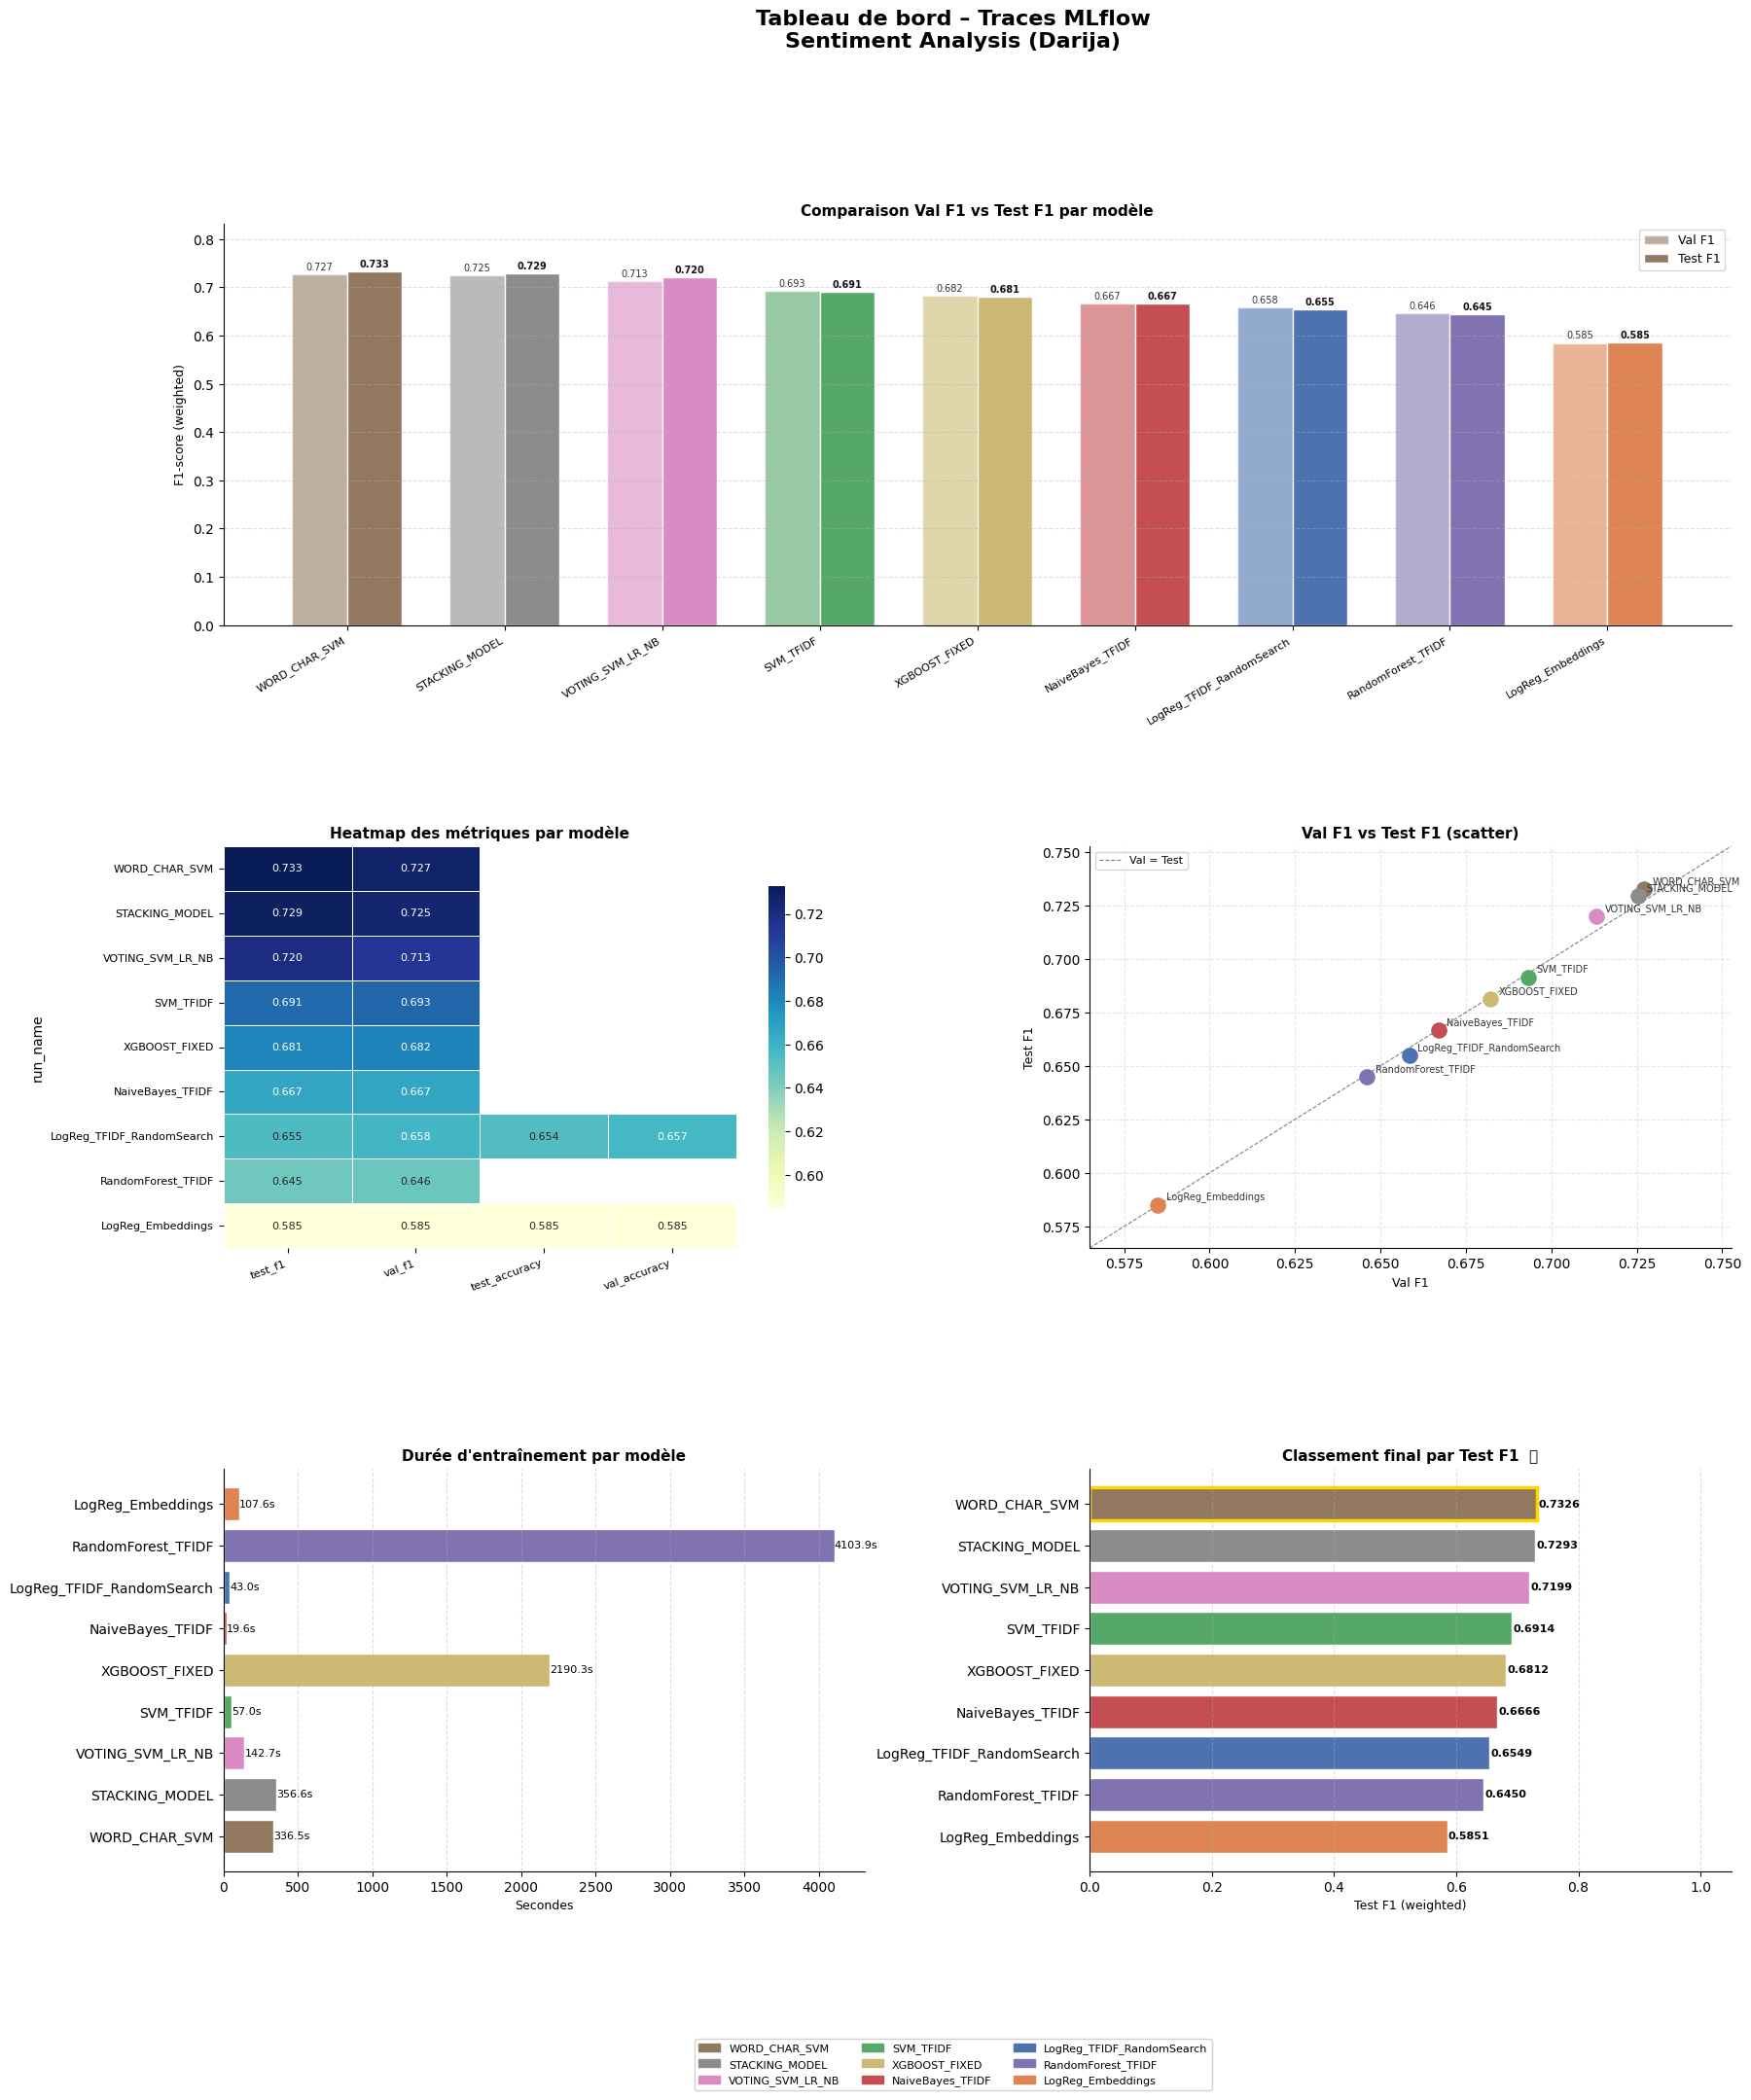

Traces exportées → traces_mlflow.csv


In [6]:
"""
=========================================================
 Affichage des traces MLflow – Sentiment Analysis Darija
 Modèles couverts :
   1. LogReg + TF-IDF (RandomSearch)
   2. LogReg + Embeddings (SentenceTransformer)
   3. SVM (LinearSVC) + TF-IDF
   4. Naive Bayes + TF-IDF
   5. Random Forest + TF-IDF
   6. SVM Word+Char (FeatureUnion)
   7. Voting Classifier (SVM+LR+NB)
   8. Stacking Classifier
   9. XGBoost + TF-IDF
=========================================================
"""

import os
import warnings
warnings.filterwarnings("ignore")

import mlflow
from mlflow.tracking import MlflowClient
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.gridspec import GridSpec

# ──────────────────────────────────────────────
# 0. Configuration
# ──────────────────────────────────────────────
TRACKING_URI = "file:./mlruns"          # adapter si besoin
mlflow.set_tracking_uri(TRACKING_URI)
client = MlflowClient(tracking_uri=TRACKING_URI)

# Palette de couleurs cohérente
PALETTE = {
    "LogReg_TFIDF_RandomSearch" : "#4C72B0",
    "LogReg_Embeddings"         : "#DD8452",
    "SVM_TFIDF"                 : "#55A868",
    "NaiveBayes_TFIDF"          : "#C44E52",
    "RandomForest_TFIDF"        : "#8172B2",
    "WORD_CHAR_SVM"             : "#937860",
    "VOTING_SVM_LR_NB"          : "#DA8BC3",
    "STACKING_MODEL"            : "#8C8C8C",
    "XGBOOST_FIXED"             : "#CCB974",
}
DEFAULT_COLOR = "#6699CC"

# ──────────────────────────────────────────────
# 1. Collecte de tous les runs MLflow
# ──────────────────────────────────────────────
def collect_all_runs() -> pd.DataFrame:
    """Parcourt toutes les expériences et renvoie un DataFrame unifié."""
    experiments = client.search_experiments()
    if not experiments:
        raise RuntimeError(
            "Aucune expérience trouvée dans le répertoire mlruns.\n"
            "Assurez-vous d'avoir lancé au moins un run avant d'afficher les traces."
        )

    records = []
    for exp in experiments:
        runs = client.search_runs(experiment_ids=[exp.experiment_id])
        for run in runs:
            row = {
                "experiment"  : exp.name,
                "run_id"      : run.info.run_id,
                "run_name"    : run.data.tags.get("mlflow.runName", run.info.run_id[:8]),
                "status"      : run.info.status,
                "start_time"  : pd.to_datetime(run.info.start_time, unit="ms"),
                "duration_s"  : (run.info.end_time - run.info.start_time) / 1000
                                if run.info.end_time else None,
            }
            row.update(run.data.metrics)
            row.update({f"param_{k}": v for k, v in run.data.params.items()})
            records.append(row)

    df = pd.DataFrame(records)
    # trier par test_f1 décroissant si dispo
    if "test_f1" in df.columns:
        df = df.sort_values("test_f1", ascending=False)
    return df.reset_index(drop=True)


# ──────────────────────────────────────────────
# 2. Résumé console
# ──────────────────────────────────────────────
def print_summary(df: pd.DataFrame) -> None:
    metric_cols = [c for c in df.columns
                   if c in ("val_f1", "test_f1",  "val_precision", "test_precision")]
    display_cols = ["run_name", "experiment", "status"] + metric_cols + ["duration_s"]
    display_cols = [c for c in display_cols if c in df.columns]

    print("\n" + "="*80)
    print("  RÉSUMÉ DES TRACES MLFLOW")
    print("="*80)
    with pd.option_context("display.max_columns", None, "display.width", 120,
                           "display.float_format", "{:.4f}".format):
        print(df[display_cols].to_string(index=False))

    if "test_f1" in df.columns:
        best = df.loc[df["test_f1"].idxmax()]
        print(f"\n  Meilleur modèle (test F1) : {best['run_name']}  →  {best['test_f1']:.4f}")
    print("="*80 + "\n")


# ──────────────────────────────────────────────
# 3. Graphiques
# ──────────────────────────────────────────────
def get_color(run_name: str) -> str:
    return PALETTE.get(run_name, DEFAULT_COLOR)


def plot_f1_comparison(df: pd.DataFrame, ax: plt.Axes) -> None:
    """Barres Val F1 vs Test F1 par modèle."""
    has_val  = "val_f1"  in df.columns
    has_test = "test_f1" in df.columns

    if not (has_val or has_test):
        ax.text(0.5, 0.5, "Aucune métrique F1 disponible",
                ha="center", va="center", transform=ax.transAxes)
        return

    names  = df["run_name"].tolist()
    x      = range(len(names))
    width  = 0.35
    colors = [get_color(n) for n in names]

    if has_val:
        bars1 = ax.bar([i - width/2 for i in x], df["val_f1"], width,
                       label="Val F1", color=colors, alpha=0.6, edgecolor="white")
        for bar in bars1:
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.005,
                    f"{bar.get_height():.3f}",
                    ha="center", va="bottom", fontsize=7, color="#333")

    if has_test:
        bars2 = ax.bar([i + width/2 for i in x], df["test_f1"], width,
                       label="Test F1", color=colors, alpha=1.0, edgecolor="white")
        for bar in bars2:
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.005,
                    f"{bar.get_height():.3f}",
                    ha="center", va="bottom", fontsize=7, color="#111", fontweight="bold")

    ax.set_xticks(list(x))
    ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("F1-score (weighted)", fontsize=9)
    ax.set_title("Comparaison Val F1 vs Test F1 par modèle", fontsize=11, fontweight="bold")
    ax.legend(fontsize=9)
    ax.set_ylim(0, min(1.05, df[["val_f1","test_f1"]].max().max() + 0.1)
                if has_val and has_test else ax.get_ylim()[1])
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top","right"]].set_visible(False)


def plot_accuracy_comparison(df: pd.DataFrame, ax: plt.Axes) -> None:
    """Accuracy val vs test si disponible."""
    has_val  = "val_accuracy"  in df.columns
    has_test = "test_accuracy" in df.columns

    if not (has_val or has_test):
        ax.text(0.5, 0.5, "Accuracy non loggée dans ces runs",
                ha="center", va="center", transform=ax.transAxes, fontsize=9)
        ax.set_title("Accuracy Val vs Test", fontsize=11, fontweight="bold")
        return

    names  = df["run_name"].tolist()
    x      = range(len(names))
    width  = 0.35
    colors = [get_color(n) for n in names]

    if has_val:
        ax.bar([i - width/2 for i in x], df["val_accuracy"], width,
               label="Val Accuracy", color=colors, alpha=0.6, edgecolor="white")
    if has_test:
        ax.bar([i + width/2 for i in x], df["test_accuracy"], width,
               label="Test Accuracy", color=colors, alpha=1.0, edgecolor="white")

    ax.set_xticks(list(x))
    ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("Accuracy", fontsize=9)
    ax.set_title("Accuracy Val vs Test par modèle", fontsize=11, fontweight="bold")
    ax.legend(fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top","right"]].set_visible(False)


def plot_val_vs_test_scatter(df: pd.DataFrame, ax: plt.Axes) -> None:
    """Scatter Val F1 vs Test F1 (détecte sur/sous-apprentissage)."""
    if "val_f1" not in df.columns or "test_f1" not in df.columns:
        ax.text(0.5, 0.5, "Val F1 ou Test F1 manquant",
                ha="center", va="center", transform=ax.transAxes)
        return

    for _, row in df.iterrows():
        color = get_color(row["run_name"])
        ax.scatter(row["val_f1"], row["test_f1"],
                   color=color, s=120, zorder=3)
        ax.annotate(row["run_name"],
                    (row["val_f1"], row["test_f1"]),
                    textcoords="offset points", xytext=(6, 4),
                    fontsize=7, color="#333")

    lims = [min(df["val_f1"].min(), df["test_f1"].min()) - 0.02,
            max(df["val_f1"].max(), df["test_f1"].max()) + 0.02]
    ax.plot(lims, lims, "k--", linewidth=0.8, alpha=0.5, label="Val = Test")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("Val F1", fontsize=9)
    ax.set_ylabel("Test F1", fontsize=9)
    ax.set_title("Val F1 vs Test F1 (scatter)", fontsize=11, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(linestyle="--", alpha=0.3)
    ax.spines[["top","right"]].set_visible(False)


def plot_duration(df: pd.DataFrame, ax: plt.Axes) -> None:
    """Durée d'entraînement par run."""
    if "duration_s" not in df.columns or df["duration_s"].isna().all():
        ax.text(0.5, 0.5, "Durée non disponible",
                ha="center", va="center", transform=ax.transAxes)
        ax.set_title("Durée d'entraînement (s)", fontsize=11, fontweight="bold")
        return

    sub = df.dropna(subset=["duration_s"])
    colors = [get_color(n) for n in sub["run_name"]]
    bars = ax.barh(sub["run_name"], sub["duration_s"], color=colors, edgecolor="white")
    for bar in bars:
        w = bar.get_width()
        ax.text(w + 0.5, bar.get_y() + bar.get_height()/2,
                f"{w:.1f}s", va="center", fontsize=8)

    ax.set_xlabel("Secondes", fontsize=9)
    ax.set_title("Durée d'entraînement par modèle", fontsize=11, fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.spines[["top","right"]].set_visible(False)


def plot_heatmap(df: pd.DataFrame, ax: plt.Axes) -> None:
    """Heatmap de toutes les métriques disponibles."""
    metric_cols = [c for c in df.columns
                   if c in ("val_f1", "test_f1", "val_accuracy",
                             "test_accuracy", "val_precision", "test_precision",
                             "val_recall", "test_recall")]
    if not metric_cols:
        ax.text(0.5, 0.5, "Pas assez de métriques pour la heatmap",
                ha="center", va="center", transform=ax.transAxes)
        ax.set_title("Heatmap des métriques", fontsize=11, fontweight="bold")
        return

    heat_data = df.set_index("run_name")[metric_cols].astype(float)
    sns.heatmap(heat_data, annot=True, fmt=".3f", cmap="YlGnBu",
                linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8},
                annot_kws={"size": 8})
    ax.set_title("Heatmap des métriques par modèle", fontsize=11, fontweight="bold")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right", fontsize=8)


def plot_ranking(df: pd.DataFrame, ax: plt.Axes) -> None:
    """Classement final par Test F1."""
    if "test_f1" not in df.columns:
        ax.text(0.5, 0.5, "test_f1 non disponible",
                ha="center", va="center", transform=ax.transAxes)
        ax.set_title("Classement final (Test F1)", fontsize=11, fontweight="bold")
        return

    ranked = df.sort_values("test_f1", ascending=True)
    colors = [get_color(n) for n in ranked["run_name"]]
    bars = ax.barh(ranked["run_name"], ranked["test_f1"],
                   color=colors, edgecolor="white")

    # surligner le meilleur
    bars[-1].set_edgecolor("gold")
    bars[-1].set_linewidth(2.5)

    for bar in bars:
        w = bar.get_width()
        ax.text(w + 0.002, bar.get_y() + bar.get_height()/2,
                f"{w:.4f}", va="center", fontsize=8, fontweight="bold")

    ax.set_xlabel("Test F1 (weighted)", fontsize=9)
    ax.set_title("Classement final par Test F1  🏆", fontsize=11, fontweight="bold")
    ax.set_xlim(0, 1.05)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.spines[["top","right"]].set_visible(False)


# ──────────────────────────────────────────────
# 4. Dashboard principal
# ──────────────────────────────────────────────
def build_dashboard(df: pd.DataFrame) -> plt.Figure:
    fig = plt.figure(figsize=(20, 22))
    fig.suptitle("Tableau de bord – Traces MLflow\nSentiment Analysis (Darija)",
                 fontsize=16, fontweight="bold", y=0.98)

    gs = GridSpec(3, 2, figure=fig, hspace=0.55, wspace=0.35)

    ax1 = fig.add_subplot(gs[0, :])          # pleine largeur
    ax2 = fig.add_subplot(gs[1, 0])
    ax3 = fig.add_subplot(gs[1, 1])
    ax4 = fig.add_subplot(gs[2, 0])
    ax5 = fig.add_subplot(gs[2, 1])

    plot_f1_comparison(df, ax1)
    plot_heatmap(df, ax2)
    plot_val_vs_test_scatter(df, ax3)
    plot_duration(df, ax4)
    plot_ranking(df, ax5)

    # légende globale
    patches = [mpatches.Patch(color=get_color(n), label=n) for n in df["run_name"]]
    fig.legend(handles=patches, loc="lower center", ncol=3,
               fontsize=8, framealpha=0.9,
               bbox_to_anchor=(0.5, 0.005))

    return fig


# ──────────────────────────────────────────────
# 5. Export CSV des traces
# ──────────────────────────────────────────────
def export_traces(df: pd.DataFrame, path: str = "traces_mlflow.csv") -> None:
    df.to_csv(path, index=False, encoding="utf-8-sig")
    print(f"Traces exportées → {path}")


# ──────────────────────────────────────────────
# 6. Point d'entrée
# ──────────────────────────────────────────────
def main() -> None:
    print("Connexion à MLflow …")
    df = collect_all_runs()

    # Exclure les runs échoués
    failed = df[df["status"] == "FAILED"]
    if not failed.empty:
        print(f"⚠️  {len(failed)} run(s) FAILED ignoré(s) : {failed['run_name'].tolist()}")
    df = df[df["status"] != "FAILED"].reset_index(drop=True)

    if df.empty:
        print("Aucun run valide trouvé.")
        return

    print_summary(df)

    print("Génération du dashboard …")
    fig = build_dashboard(df)

    out_png = "dashboard_traces_mlflow.png"
    fig.savefig(out_png, dpi=150, bbox_inches="tight")
    print(f"Dashboard sauvegardé → {out_png}")
    plt.show()

    export_traces(df)


if __name__ == "__main__":
    main()